# Diseño y Análisis de Experimentos
## Experimento $2^{5-1}$: ejemplo integrador (Cap. 8)

Misma planta de semiconductores del experimento $2^5$ (factores A–E, respuesta = rendimiento). Se muestra que con **solo la mitad de las corridas** (fracción $2^{5-1}$, 16 corridas) se llega a las mismas conclusiones que con el factorial completo.

**Construcción (libro):** 1) se escribe el $2^4$ en A, B, C, D; 2) la columna E es el producto de las cuatro primeras.

- Fracción **principal**: $E=ABCD \Rightarrow I=ABCDE$.
- Fracción **complementaria**: $E=-ABCD \Rightarrow I=-ABCDE$.

Es un diseño de **resolución V**: los efectos principales se confunden con interacciones de 4 factores y las dobles con las de 3, que son despreciables.

## 1. Datos (Tabla 8.4)

In [1]:
import itertools
import numpy as np
import pandas as pd
from scipy import stats

principal = {  # tratamiento: rendimiento
 "e":18,"d":8,"a":9,"ade":10,"b":34,"bde":30,"abe":52,"abd":50,
 "c":16,"cde":15,"ace":22,"acd":21,"bce":45,"bcd":44,"abc":60,"abcde":63}
complementaria = {
 "(1)":7,"de":6,"ae":12,"ad":10,"be":35,"bd":32,"ab":55,"abde":53,
 "ce":15,"cd":18,"ac":20,"acde":20,"bc":40,"bcde":41,"abce":65,"abcd":61}

def a_signos(trat):
    """tratamiento (p. ej. 'abe') -> niveles -1/+1 de A..E"""
    t = "" if trat == "(1)" else trat
    return [1 if f in t else -1 for f in "abcde"]

def armar(d):
    df = pd.DataFrame([a_signos(k) + [v] for k, v in d.items()], index=list(d), columns=list("ABCDE") + ["Y"])
    return df

fp, fc = armar(principal), armar(complementaria)
print("Producto ABCDE en la fracción principal:     ", set(fp[list("ABCDE")].prod(axis=1)))
print("Producto ABCDE en la fracción complementaria:", set(fc[list("ABCDE")].prod(axis=1)))
fp

Producto ABCDE en la fracción principal:      {1}
Producto ABCDE en la fracción complementaria: {-1}


,A,B,C,D,E,Y
e,-1,-1,-1,-1,1,18
d,-1,-1,-1,1,-1,8
a,1,-1,-1,-1,-1,9
ade,1,-1,-1,1,1,10
b,-1,1,-1,-1,-1,34
bde,-1,1,-1,1,1,30
abe,1,1,-1,-1,1,52
abd,1,1,-1,1,-1,50
c,-1,-1,1,-1,-1,16
cde,-1,-1,1,1,1,15


> **Dato a revisar.** En la Tabla 8.4 impresa aparece $e=8.0$, mientras que en la Tabla 6.14 del mismo experimento $e=18$. Se usa **18** (consistente con la 6.14 y con la afirmación del libro de que ambas fracciones dan el mismo ANOVA). Al final se muestra el efecto de usar 8.0.

## 2. Efectos de cada fracción

Con 16 corridas: $\text{Efecto}=\text{Contraste}/8$ y $SC=\text{Contraste}^2/16$. Cada efecto de la fracción es una *suma de alias* (p. ej. $A+BCDE$).

In [2]:
def efectos(df):
    n = len(df); filas = []
    for r in range(1, 6):
        for c in itertools.combinations(range(5), r):
            signo = np.prod(df[list("ABCDE")].values[:, c], axis=1)
            con = signo @ df.Y.values
            filas.append(("".join("ABCDE"[i] for i in c), r, con / (n / 2), con**2 / n))
    return pd.DataFrame(filas, columns=["Efecto", "Orden", "Estimación", "SC"]).set_index("Efecto")

ep, ec = efectos(fp), efectos(fc)
# Solo hay 15 contrastes independientes: se conservan principales + dobles (orden<=2)
tp = ep[ep.Orden <= 2].copy(); tc = ec[ec.Orden <= 2].copy()
comp = pd.DataFrame({"Efecto principal": tp.Estimación, "Efecto complementaria": tc.Estimación,
                     "SC principal": tp.SC, "SC complementaria": tc.SC}).round(3)
comp.sort_values("SC principal", ascending=False)

,Efecto principal,Efecto complementaria,SC principal,SC complementaria
Efecto,,,,
B,32.375,34.25,4192.562,4692.25
A,9.625,12.75,370.562,650.25
C,9.375,8.75,351.562,306.25
AB,8.375,8.75,280.562,306.25
DE,-2.875,-0.75,33.062,2.25
AD,2.125,-1.00,18.062,4.00
BC,2.125,-0.75,18.062,2.25
D,-1.875,-1.00,14.062,4.00
AC,1.875,0.25,14.062,0.25


Ambas fracciones señalan los mismos efectos: **B, A, C y AB**. Los signos de las estimaciones pueden cambiar en algunos efectos pequeños porque cada fracción estima alias distintos.

## 3. Análisis de varianza

En un $2^{5-1}$ de resolución V hay 15 contrastes (5 principales + 10 dobles) y 15 g.l.: el modelo con todos los efectos es **saturado** (0 g.l. de error). Por eso se conservan solo los efectos que destacan (A, B, C, AB) y el resto pasa al error (11 g.l.).

In [3]:
def anova(e, mejor=("A", "B", "C", "AB"), gl_total=15):
    sc = e.loc[list(mejor), "SC"]
    sct = e[e.Orden <= 2]["SC"].sum()
    sce = sct - sc.sum(); gle = gl_total - len(mejor); cme = sce / gle
    t = pd.DataFrame({"SC": sc, "gl": 1, "CM": sc})
    t["F"] = t.CM / cme; t["p-valor"] = stats.f.sf(t.F, 1, gle)
    t.loc["Residual"] = [sce, gle, cme, np.nan, np.nan]
    return t, sc.sum() / sct, 1 - (sce / gle) / (sct / gl_total)

for nombre, e in (("Fracción principal", ep), ("Fracción complementaria", ec)):
    t, r2, r2a = anova(e)
    print(f"== {nombre} ==  R² = {r2:.4f} | R² aj = {r2a:.4f}")
    display(t.round(4))

== Fracción principal ==  R² = 0.9753 | R² aj = 0.9663


,SC,gl,CM,F,p-valor
Efecto,,,,,
A,370.5625,1.0,370.5625,30.9535,0.0002
B,4192.5625,1.0,4192.5625,350.2093,0.0000
C,351.5625,1.0,351.5625,29.3664,0.0002
AB,280.5625,1.0,280.5625,23.4357,0.0005
Residual,131.6875,11.0,11.9716,NaN,NaN


== Fracción complementaria ==  R² = 0.9955 | R² aj = 0.9939


,SC,gl,CM,F,p-valor
Efecto,,,,,
A,650.25,1.0,650.2500,267.3925,0.0
B,4692.25,1.0,4692.2500,1929.5234,0.0
C,306.25,1.0,306.2500,125.9346,0.0
AB,306.25,1.0,306.2500,125.9346,0.0
Residual,26.75,11.0,2.4318,NaN,NaN


## 4. Comparación con el factorial completo $2^5$

| Efecto | SC completo (32 corridas) | SC fracción principal (16) | SC fracción compl. (16) |
|---|---|---|---|

In [4]:
sc_completo = {"A":1001.2812,"B":8877.7812,"C":657.0312,"AB":586.5312}   # notebook del 2^5
pd.DataFrame({"SC completo (32)": pd.Series(sc_completo),
              "SC principal (16)": ep.loc[list(sc_completo), "SC"],
              "SC complementaria (16)": ec.loc[list(sc_completo), "SC"]}).round(3)

,SC completo (32),SC principal (16),SC complementaria (16)
A,1001.281,370.562,650.25
B,8877.781,4192.562,4692.25
C,657.031,351.562,306.25
AB,586.531,280.562,306.25


Las SC de las fracciones son aproximadamente la mitad de las del completo (16 vs 32 corridas, mismos contrastes), y el orden de importancia **B > A > C > AB** se conserva. Los resultados son parecidos pero no idénticos porque cada fracción solo observa la mitad de las combinaciones.

## 5. Pareto y probabilidad normal (ambas fracciones)

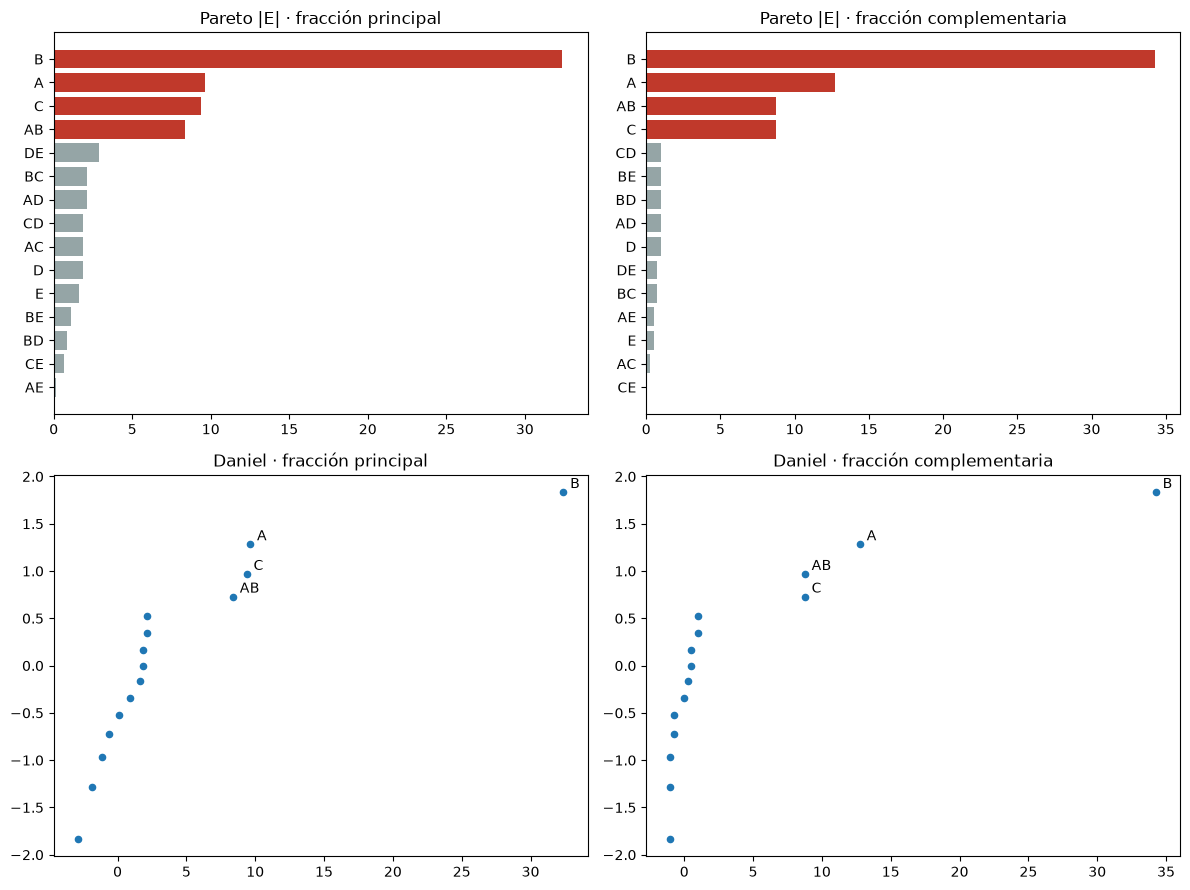

In [5]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(2, 2, figsize=(12, 9))
for j, (nombre, e) in enumerate((("Principal", ep), ("Complementaria", ec))):
    ef = e[e.Orden <= 2]["Estimación"]
    o = ef.abs().sort_values()
    ax[0, j].barh(o.index, o.values, color=["#c0392b" if k in ("A","B","C","AB") else "#95a5a6" for k in o.index])
    ax[0, j].set_title(f"Pareto |E| · fracción {nombre.lower()}")
    s = np.sort(ef.values); q = stats.norm.ppf((np.arange(1, len(s)+1) - .5) / len(s))
    ax[1, j].scatter(s, q, s=20)
    for xi, qi, nm in zip(s, q, ef.sort_values().index):
        if nm in ("A","B","C","AB"): ax[1, j].annotate(nm, (xi, qi), xytext=(5, 3), textcoords="offset points")
    ax[1, j].set_title(f"Daniel · fracción {nombre.lower()}")
plt.tight_layout(); plt.show()

## 6. Sensibilidad al dato $e=8.0$ (Tabla 8.4 impresa)

In [6]:
alt = dict(principal); alt["e"] = 8
ea = efectos(armar(alt))
t, r2, r2a = anova(ea)
print("Con e = 8.0:  R² =", round(r2, 4))
display(t.round(4))

Con e = 8.0:  R² = 0.9944


,SC,gl,CM,F,p-valor
Efecto,,,,,
A,473.0625,1.0,473.0625,164.2189,0.0
B,4522.5625,1.0,4522.5625,1569.9625,0.0
C,451.5625,1.0,451.5625,156.7554,0.0
AB,203.0625,1.0,203.0625,70.4911,0.0
Residual,31.6875,11.0,2.8807,NaN,NaN


Con $e=8$ las conclusiones principales (B, A, C, AB) no cambian, aunque varían algo las SC. La Tabla 6.14 (e = 18) es la consistente con el factorial completo.

## 7. Cómo se hizo en la calculadora del profesor

Pestaña **Diseño Interactivo** → *Screening (Factorial 2^k)*:

1. Paso 1: Screening (Factorial 2^k).
2. Paso 2: **4 factores** (A–D).
3. Paso 3: respuesta = Rendimiento.
4. Paso 4: 1 réplica, 0 puntos centrales, sin randomizar → *Generar Diseño* (16 corridas).
5. Paso 5: carga por CSV de la fracción principal con A–D y Y (E = ABCD queda implícita).
6. Paso 6: ANOVA Tipo I.
7. Paso 7: *Refinamiento*: se dejan A, B, C y AB → *Recalcular Modelo Reducido*.

**Resultado de la calculadora (mejor ANOVA, fracción principal):**

| Fuente | gl | SC | F | p |
|---|---|---|---|---|
| A | 1 | 370.5625 | 30.95 | 0.000169 |
| B | 1 | 4192.5625 | 350.21 | 0.000000 |
| C | 1 | 351.5625 | 29.37 | 0.000210 |
| AB | 1 | 280.5625 | 23.44 | 0.000518 |
| Residual | 11 | 131.6875 | | |

R² = 0.9753 · R² ajustado = 0.9663.

**Limitaciones encontradas en la app:**

- Con **5 factores y 16 corridas** el wizard falla (`shapes (32,32) and (16,) not aligned`): arma el modelo completo de 5 factores (32 términos), que no se puede ajustar con 16 corridas. Por eso se usó el $2^4$ con E = ABCD, tal como describe el libro.
- En la pestaña *Fraccionado*, con k = 5 la app lanza `StreamlitValueAboveMaxError` porque el valor por defecto p = 4 excede el máximo permitido (k − 2).
- En el wizard con 4 factores, la columna E aparece como el término `Factor_A:Factor_B:Factor_C:Factor_D`.

## 8. Conclusión

La fracción $2^{5-1}$ (16 corridas, mitad del costo) identifica los mismos efectos activos que el factorial completo: **A, B, C y AB**, con B como el dominante. D, E y el resto de las interacciones no son significativos.